# Q5. Kỹ năng nào được tuyển nhiều nhất theo ngành? Kỹ năng nào gắn với lương cao hơn?
**Người phụ trách:** Thành viên 3

**Phương pháp:** `technical_skills` là văn bản tự do (~29.000 cách viết) → gom về 32 nhóm kỹ năng bằng regex
(`src/taxonomy.py`). Đếm theo ngành; với mỗi kỹ năng có ≥ 100 tin có lương: so sánh trung vị lương **trong cùng ngành**
(có vs không có kỹ năng) rồi lấy trung bình có trọng số — tránh nhầm "kỹ năng IT lương cao" chỉ vì ngành IT lương cao.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.cleaning import load_clean, EXPERIENCE_LEVELS, REGIONS, CATEGORY_LABELS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_clean()
df["cat"] = df["category"].map(CATEGORY_LABELS)
# Tập có lương hợp lệ: bỏ "Thoả thuận" và ngoại lai
sal = df[~df["salary_negotiable"] & ~df["salary_outlier"]].copy()
print(f"Tất cả tin: {len(df):,} | Tin có lương hợp lệ: {len(sal):,}")

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

Tất cả tin: 36,457 | Tin có lương hợp lệ: 25,796


Tin có ≥1 nhóm kỹ năng nhận diện được: 58.9% (tin có liệt kê kỹ năng: 87.3%)


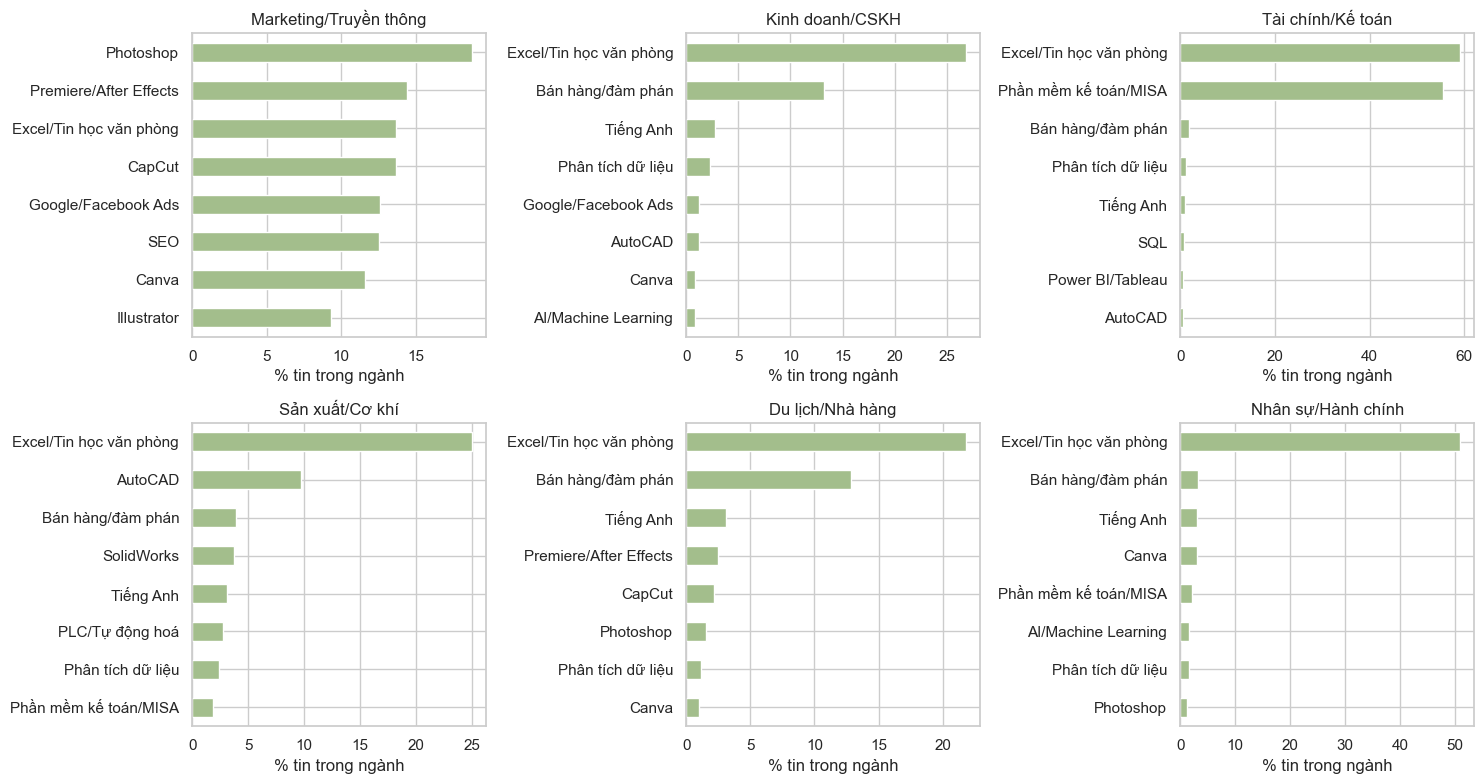

In [2]:
from src.taxonomy import SKILL_GROUPS, tag_items
df["skill_tags"] = df["technical_skills_list"].map(lambda l: tag_items(l, SKILL_GROUPS))
print(f"Tin có ≥1 nhóm kỹ năng nhận diện được: {(df.skill_tags.map(len) > 0).mean():.1%} "
      f"(tin có liệt kê kỹ năng: {(df.n_technical_skills > 0).mean():.1%})")
top_cats = df["cat"].value_counts().head(6).index
ex = df[["cat", "skill_tags"]].explode("skill_tags").dropna()
share = (ex.groupby("cat")["skill_tags"].value_counts() / df["cat"].value_counts()).mul(100).rename("% tin")
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, top_cats):
    share.loc[c].sort_values(ascending=False).head(8).sort_values().plot.barh(ax=ax, color="#a3be8c")
    ax.set(title=c, xlabel="% tin trong ngành", ylabel="")
savefig("q5_top_skills_by_category.png")

## Kỹ năng gắn với lương cao (so sánh trong cùng ngành)

,số tin,trung vị có (triệu),chênh lệch thô,chênh lệch trong ngành
kỹ năng,,,,
SQL,224,22.0,9.0,7.5
Python,103,22.0,9.0,6.2
JavaScript,123,23.0,10.0,6.0
Digital marketing,199,17.0,4.0,4.7
Quản lý dự án,263,17.0,4.0,3.9
Bán hàng/đàm phán,1504,15.0,2.0,2.8
Phân tích dữ liệu,526,15.0,2.0,2.6
SolidWorks,241,15.0,2.0,2.5
Google Analytics,277,14.0,1.0,2.0


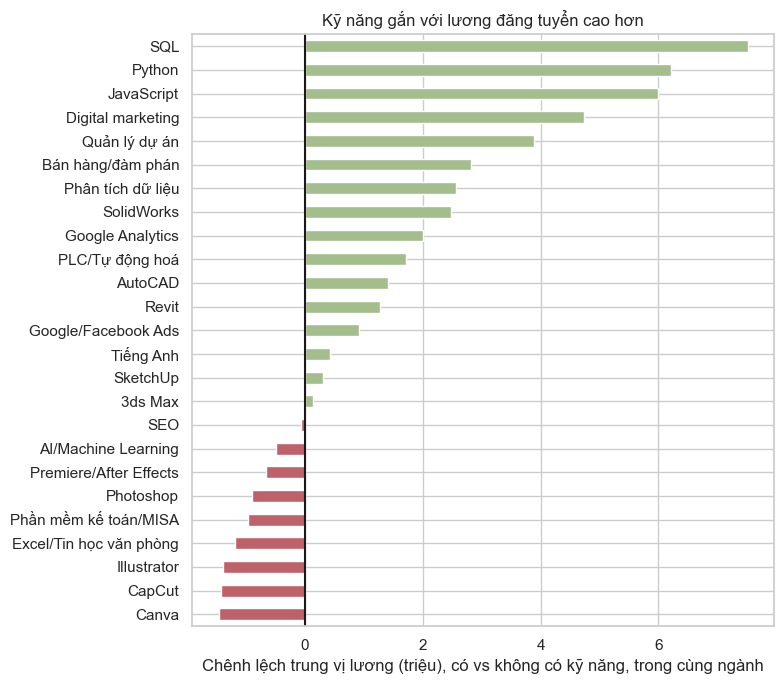

In [3]:
s = df[~df.salary_negotiable & ~df.salary_outlier]
rows = []
for skill in SKILL_GROUPS:
    has = s["skill_tags"].map(lambda t: skill in t)
    if has.sum() < 100:
        continue
    diffs, weights = [], []
    for c, g in s.groupby("cat"):
        h = has.loc[g.index]
        if h.sum() >= 10 and (~h).sum() >= 10:
            diffs.append(g.loc[h, "salary_avg_num"].median() - g.loc[~h, "salary_avg_num"].median())
            weights.append(h.sum())
    rows.append({"kỹ năng": skill, "số tin": int(has.sum()),
                 "trung vị có (triệu)": s.loc[has, "salary_avg_num"].median(),
                 "chênh lệch thô": s.loc[has, "salary_avg_num"].median() - s.loc[~has, "salary_avg_num"].median(),
                 "chênh lệch trong ngành": np.average(diffs, weights=weights) if diffs else np.nan})
prem = pd.DataFrame(rows).set_index("kỹ năng").sort_values("chênh lệch trong ngành", ascending=False)
display(prem.round(1))
v = prem["chênh lệch trong ngành"].dropna().sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
v.plot.barh(ax=ax, color=np.where(v > 0, "#a3be8c", "#bf616a"))
ax.axvline(0, c="k")
ax.set(xlabel="Chênh lệch trung vị lương (triệu), có vs không có kỹ năng, trong cùng ngành", ylabel="",
       title="Kỹ năng gắn với lương đăng tuyển cao hơn")
savefig("q5_skill_salary_premium.png")

## Kết luận

In [4]:
overall_top = ex["skill_tags"].value_counts()
print(f"- Kỹ năng được yêu cầu nhiều nhất: {', '.join(overall_top.index[:3])}.")
pp = prem["chênh lệch trong ngành"].dropna()
print(f"- Gắn với lương cao hơn nhất (trong cùng ngành): {pp.index[0]} ({pp.iloc[0]:+.1f} triệu), "
      f"{pp.index[1]} ({pp.iloc[1]:+.1f}), {pp.index[2]} ({pp.iloc[2]:+.1f}).")
print(f"- Thấp nhất: {pp.index[-1]} ({pp.iloc[-1]:+.1f} triệu).")

- Kỹ năng được yêu cầu nhiều nhất: Excel/Tin học văn phòng, Phần mềm kế toán/MISA, AutoCAD.
- Gắn với lương cao hơn nhất (trong cùng ngành): SQL (+7.5 triệu), Python (+6.2), JavaScript (+6.0).
- Thấp nhất: Canva (-1.5 triệu).


**Hạn chế chung:** dữ liệu chỉ từ TopCV (2025), là **lương đăng tuyển** (không phải lương thực nhận),
và ~29% tin không công bố lương. Kết luận chỉ mô tả thị trường tin tuyển dụng trên nền tảng này.

Chênh lệch là **tương quan**, không phải nhân quả.
*Nhận xét trên được sinh tự động từ số liệu — thành viên phụ trách cần đọc lại và diễn giải bằng lời của mình.*